Deliverable 1 in INF 201

Task 1: 

Summary of temperatures this year (2025) in Ås:
Mean temperature of the year:               7.9°C 
Median temperature of the year:             8.4°C 
Lowest temperature of the year:           -15.5°C
Highest temperature of the year:           23.7°C


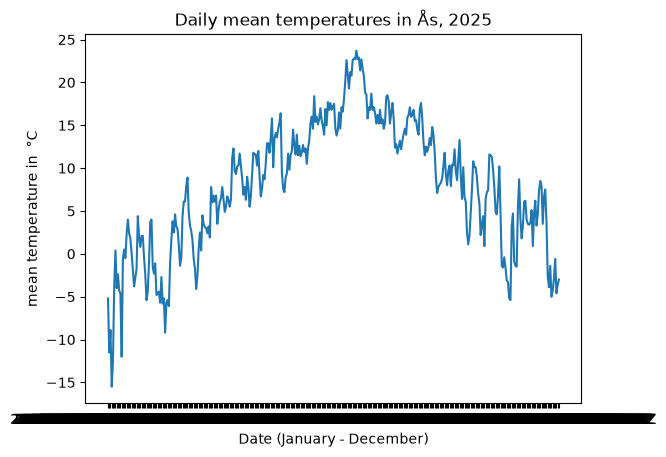

In [ ]:
""" Takes the daily mean temperature in Ås in 2025, from frost.met.no
and turns it into a graph. It also calculates mean, median, highest and lowest
temperature of 2025, and prints out the results.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests

file_path = Path.home() / 'INF201' / 'FrostID.txt'
with open(file_path, "r") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, params=parameters, auth=(client_id, ''), timeout=10)
json_data = r.json()

if r.status_code == 200:
    xtime: list[str] = []
    ytemperature: list[float]= []

    for day in json_data['data']:
        date = day['referenceTime']
        temp = day['observations'][0]['value']
    
        xtime.append(date)
        ytemperature.append(temp)

    mean_year_temp = np.mean(ytemperature)
    median_year_temp = np.median(ytemperature)
    min_year_temp = np.min(ytemperature)
    max_year_temp = np.max(ytemperature)
        
    print("Summary of temperatures this year (2025) in Ås:")
    print(f"{'Mean temperature of the year:' :<33} {mean_year_temp:>13.1f}°C ")
    print(f"{'Median temperature of the year:' :<33} {median_year_temp:>13.1f}°C ")
    print(f"{'Lowest temperature of the year:' :<33} {min_year_temp:>13.1f}°C")
    print(f"{'Highest temperature of the year:' :<33} {max_year_temp:>13.1f}°C")

    plt.plot(xtime, ytemperature)
    plt.title('Daily mean temperatures in Ås, 2025')
    plt.xlabel('Date (January - December)')
    plt.ylabel('mean temperature in  °C')
    plt.show()

else:
    print(f"Something happened! statuscode: {r.status_code}")
    print(json_data.get('error', {}).get('message'))


Refrences: 
Meteorologisk institutt (u.å) https://frost.met.no/python_example.html Python example script Hentet[15.10.2026]
From this source i used these lines in my code:  
"import requests"
"r = requests.get(endpoint, params=parameters, auth=(client_id, ''))"
"json_data = r.json()"
"if r.status_code == 200:"

And this is pasted in from the task: 
"endpoint = 'https://frost.met.no/observations/v0.jsonld'"
"parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}"


Task 2: 

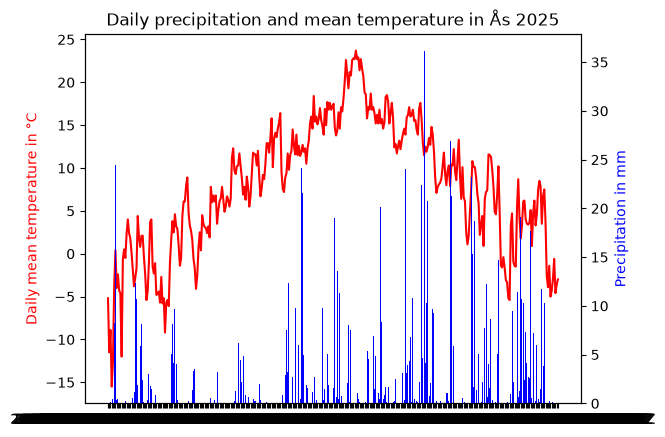

In [2]:
"""Take mean daily temperature and daily precipitation from frost.met.no
and make a graph with both variables.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import requests

file_path = Path.home() / 'INF201' / 'FrostID.txt'
with open(file_path, "r") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters_temp = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}
parameters_precip = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, params=parameters_temp, auth=(client_id, ''), timeout=10)
json_data = r.json()

r1 = requests.get(endpoint, params=parameters_precip, auth=(client_id, ''), timeout=10)
json_data1 = r1.json() 

if r.status_code == 200:
    xtime: list[str] = []
    ytemperature: list[float] = []

    for day in json_data['data']:
        date = day['referenceTime']
        temp = day['observations'][0]['value']
    
        xtime.append(date)
        ytemperature.append(temp)

else:
    print(f"Something happened! statuscode: {r.status_code}")
    print(json_data.get('error', {}).get('message'))

if r1.status_code == 200:
    all_precipitation: list[float] = []

    for precip in json_data1['data']:
        precipitation = precip['observations'][0]['value']
        all_precipitation.append(precipitation)

else:
    print(f"Something happened! statuscode: {r1.status_code}")
    print(json_data1.get('error', {}).get('message'))

fig, ax1 = plt.subplots()
ax1.plot(xtime, ytemperature, color='red', label='temperature')
ax1.set_ylabel('Daily mean temperature in °C', color='red')

ax2 = ax1.twinx()
ax2.bar(xtime, all_precipitation, color='blue', label='precipitation')
ax2.set_ylabel("Precipitation in mm", color='blue')

plt.xlabel('Date (January - December)')
plt.title("Daily precipitation and mean temperature in Ås 2025")
plt.show()

